In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv("Housing.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64


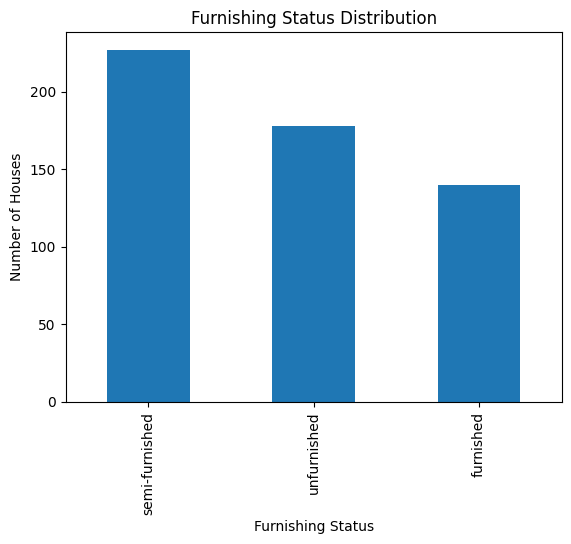

In [3]:
print(df["furnishingstatus"].value_counts())

df["furnishingstatus"].value_counts().plot(kind="bar")

plt.title("Furnishing Status Distribution")
plt.xlabel("Furnishing Status")
plt.ylabel("Number of Houses")
plt.show()

In [4]:
X = df.drop("furnishingstatus", axis=1)
y = df["furnishingstatus"]

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea']
Target: furnishingstatus


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 436
Testing rows: 109


In [6]:
numeric_cols = X.select_dtypes(include="number").columns.tolist()
category_cols = X.select_dtypes(include="object").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore",
                                  sparse_output=False))
    ]), category_cols)
])

In [7]:
model = Pipeline([
    ("preprocessing", preprocessor),
    ("naive_bayes", GaussianNB())
])

model.fit(X_train, y_train)

print("Naive Bayes trained successfully!")

Naive Bayes trained successfully!


In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.3853

Classification Report:
                precision    recall  f1-score   support

     furnished       0.36      0.64      0.46        28
semi-furnished       0.46      0.13      0.21        45
   unfurnished       0.39      0.50      0.44        36

      accuracy                           0.39       109
     macro avg       0.40      0.43      0.37       109
  weighted avg       0.41      0.39      0.35       109



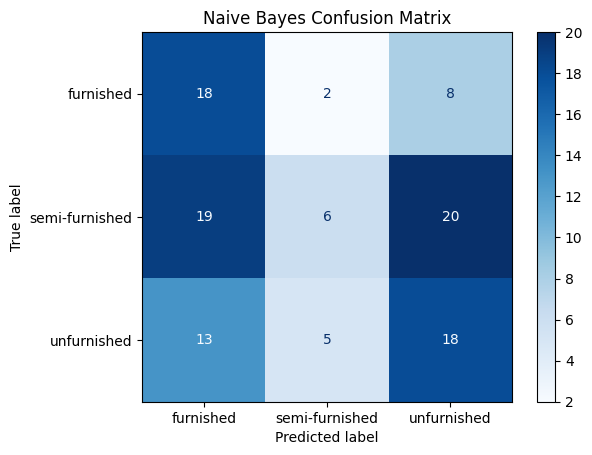

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Naive Bayes Confusion Matrix")
plt.show()

In [10]:
os.makedirs("saved_models", exist_ok=True)

joblib.dump(model, "saved_models/naive_bayes.joblib")

print("Naive Bayes model saved successfully!")

Naive Bayes model saved successfully!
